In [1]:
import torch
import torch.nn.functional as F
import cv2
from executorch.runtime import Runtime, Program, Method
import numpy as np
import math
from matplotlib import pyplot as plt
import matplotlib.patches as patches

W1010 11:37:00.046000 87924 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.

A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start(

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



ImportError: numpy.core.multiarray failed to import

In [ ]:
class CTCLabelConverter(object):
    """Convert between text-label and text-index"""

    def __init__(self, character, separator_list={}, dict_pathlist={}):
        # character (str): set of the possible characters.
        dict_character = list(character)

        self.dict = {}
        for i, char in enumerate(dict_character):
            self.dict[char] = i + 1

        # dummy '[blank]' token for CTCLoss (index 0)
        self.character = ["[blank]"] + dict_character

        self.separator_list = separator_list
        separator_char = []
        for lang, sep in separator_list.items():
            separator_char += sep
        self.ignore_idx = [0] + [i + 1 for i, item in enumerate(separator_char)]

    def decode_greedy(self, text_index, length):
        """convert text-index into text-label."""
        texts = []
        index = 0
        t = text_index[index : index + length[0]]
        # Returns a boolean array where true is when the value is not repeated
        a = np.insert(~(t[1:] == t[:-1]), 0, True)
        # Returns a boolean array where true is when the value is not in the ignore_idx list
        b = ~np.isin(t, np.array(self.ignore_idx))
        # Combine the two boolean array
        c = a & b
        # Gets the corresponding character according to the saved indexes

        text = "".join(np.array(self.character)[t[c.nonzero()]])
        texts.append(text)
        return texts

In [ ]:
class OCRUtils:
    @staticmethod
    def normalizeMeanVariance(
        in_img, mean=(0.485, 0.456, 0.406), variance=(0.229, 0.224, 0.225)
    ):
        img = in_img.copy().astype(np.float32)
        img -= np.array(
            [mean[0] * 255.0, mean[1] * 255.0, mean[2] * 255.0], dtype=np.float32
        )
        img /= np.array(
            [variance[0] * 255.0, variance[1] * 255.0, variance[2] * 255.0],
            dtype=np.float32,
        )
        return img

    @staticmethod
    def resize_with_padding(img, desired_width, desired_height):
        height, width = img.shape[:2]
        height_ratio, width_ratio = desired_height / height, desired_width / width
        resize_ratio = min(height_ratio, width_ratio)
        new_width = int(width * resize_ratio)
        new_height = int(height * resize_ratio)
        resized_img = cv2.resize(
            img, (new_width, new_height), interpolation=cv2.INTER_AREA
        )

        # Estimating the background color by sampling from the corners of the image
        corner_patch_size = max(1, min(height, width) // 30)
        corners = [
            img[0:corner_patch_size, 0:corner_patch_size],
            img[0:corner_patch_size, width - corner_patch_size : width],
            img[height - corner_patch_size : height, 0:corner_patch_size],
            img[height - corner_patch_size : height, width - corner_patch_size : width],
        ]

        if len(img.shape) == 3:  # Color image with 3 channels
            background_color = np.mean(
                [np.mean(corner, axis=(0, 1)) for corner in corners], axis=0
            ).astype(int)
            background_color = np.round(background_color).astype(int)
        else:  # Grayscale image
            background_color = np.mean([np.mean(corner) for corner in corners]).astype(
                int
            )
        # Compute padding sizes
        delta_w = desired_width - new_width
        delta_h = desired_height - new_height
        top, bottom = delta_h // 2, delta_h - (delta_h // 2)
        left, right = delta_w // 2, delta_w - (delta_w // 2)
        # Apply padding with the estimated background color
        centered_img = cv2.copyMakeBorder(
            resized_img,
            top,
            bottom,
            left,
            right,
            cv2.BORDER_CONSTANT,
            value=background_color.tolist(),
        )

        return centered_img

    @staticmethod
    def getDetBoxes(
        textmap, linkmap, text_threshold, link_threshold, low_text=0.4, sum=True
    ):
        linkmap = linkmap.copy()
        textmap = textmap.copy()

        img_h, img_w = textmap.shape
        """ labeling method """
        ret, text_score = cv2.threshold(textmap, low_text, 1, 0)
        ret, link_score = cv2.threshold(linkmap, link_threshold, 1, 0)
        if sum:
            text_score_comb = np.clip((text_score + link_score), 0, 1)
            text_score_comb = cv2.dilate(
                text_score_comb, np.ones((3, 3), np.uint8), iterations=2
            )
        else:
            text_score_comb = np.clip((text_score - link_score), 0, 1)
            kernel = np.ones((3, 3), np.uint8)
            text_score_comb = cv2.erode(text_score_comb, kernel, iterations=1)
            text_score_comb = cv2.dilate(text_score_comb, kernel, iterations=4)
        nLabels, labels, stats, centroids = cv2.connectedComponentsWithStats(
            text_score_comb.astype(np.uint8), connectivity=4
        )
        det = []
        for k in range(1, nLabels):
            # size filtering
            size = stats[k, cv2.CC_STAT_AREA]
            if size < 20:
                continue
            if sum and stats[k, cv2.CC_STAT_HEIGHT] < stats[k, cv2.CC_STAT_WIDTH]:
                continue
            # if np.max(textmap[labels == k]) < text_threshold:
            #     continue

            # make segmentation map
            segmap = np.zeros(textmap.shape, dtype=np.uint8)
            segmap[labels == k] = 255
            # remove link area
            segmap[np.logical_and(link_score == 1, text_score == 0)] = 0
            x, y = stats[k, cv2.CC_STAT_LEFT], stats[k, cv2.CC_STAT_TOP]
            w, h = stats[k, cv2.CC_STAT_WIDTH], stats[k, cv2.CC_STAT_HEIGHT]
            niter = int(math.sqrt(size * min(w, h) / (w * h)) * 2)
            sx, ex, sy, ey = x - niter, x + w + niter + 1, y - niter, y + h + niter + 1
            # boundary check
            if sx < 0:
                sx = 0
            if sy < 0:
                sy = 0
            if ex >= img_w:
                ex = img_w
            if ey >= img_h:
                ey = img_h
            kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (1 + niter, 1 + niter))
            segmap[sy:ey, sx:ex] = cv2.dilate(
                segmap[sy:ey, sx:ex], kernel, iterations=2
            )

            np_contours = (
                np.roll(np.array(np.where(segmap != 0)), 1, axis=0)
                .transpose()
                .reshape(-1, 2)
            )
            rectangle = cv2.minAreaRect(np_contours)
            box = cv2.boxPoints(rectangle)
            startidx = box.sum(axis=1).argmin()
            box = np.roll(box, 4 - startidx, 0)
            box = np.array(box)
            det.append((box, rectangle[2]))
        return det

    @staticmethod
    def adjustResultCoordinates(polys, ratio_w, ratio_h, ratio_net=2):
        if len(polys) > 0:
            for k in range(len(polys)):
                polyss = np.array(polys[k][0])
                if polyss is not None:
                    polyss *= (ratio_w * ratio_net, ratio_h * ratio_net)
                polys[k] = (polyss, polys[k][1])
        return polys

    @staticmethod
    def contrast_grey(img):
        high = np.percentile(img, 90)
        low = np.percentile(img, 10)
        return (high - low) / np.maximum(10, high + low), high, low

    @staticmethod
    def adjust_contrast_grey(img, target=0.4):
        contrast, high, low = OCRUtils.contrast_grey(img)
        if contrast < target:
            img = img.astype(int)
            ratio = 200.0 / np.maximum(10, high - low)
            img = (img - low + 25) * ratio
            img = np.maximum(
                np.full(img.shape, 0), np.minimum(np.full(img.shape, 255), img)
            ).astype(np.uint8)
        return img

    @staticmethod
    def calculate_ratio(width, height):
        """
        Calculate aspect ratio for normal use case (w>h) and vertical text (h>w)
        """
        ratio = width / height
        if ratio < 1.0:
            ratio = 1.0 / ratio
        return ratio

    @staticmethod
    def compute_ratio_and_resize(img, width, height, model_height):
        """
        Calculate ratio and resize correctly for both horizontal text
        and vertical case
        """
        ratio = width / height
        if ratio < 1.0:
            ratio = OCRUtils.calculate_ratio(width, height)
            img = cv2.resize(
                img,
                (model_height, int(model_height * ratio)),
                interpolation=cv2.INTER_LANCZOS4,
            )
        else:
            img = cv2.resize(
                img,
                (int(model_height * ratio), model_height),
                interpolation=cv2.INTER_LANCZOS4,
            )
        return img

    @staticmethod
    def normalize_for_detector(image, adjust_contrast=0.0):
        if adjust_contrast > 0:
            image = OCRUtils.adjust_contrast_grey(image, target=adjust_contrast)

        desired_width = 64
        if image.shape[1] >= 512:
            desired_width = 512
        elif image.shape[1] >= 256:
            desired_width = 256
        elif image.shape[1] >= 128:
            desired_width = 128
        image = OCRUtils.resize_with_padding(image, desired_width, 64)
        image = (image / 255.0 - 0.5) * 2.0

        image = torch.from_numpy(image).unsqueeze(0).float()
        return image

In [ ]:
def normalize_angle(angle):
    """Normalize the angle returned by OpenCV's minAreaRect."""
    if angle > 45:
        angle -= 90
    return angle


def distance(p1, p2):
    """Calculate the Euclidean distance between two points."""
    return math.sqrt((p2[0] - p1[0]) ** 2 + (p2[1] - p1[1]) ** 2)


def midpoint(p1, p2):
    """Calculate the midpoint of two points."""
    return ((p1[0] + p2[0]) / 2, (p1[1] + p2[1]) / 2)


def fit_line_to_shortest_sides(points):
    """Fit a line to the shortest sides of a rectangle, if the line is almost vertical fit it as x function of y."""
    sides = []
    midpoints = []
    for i in range(4):
        p1 = points[i]
        p2 = points[(i + 1) % 4]
        side_length = distance(p1, p2)
        sides.append((side_length, i))
        midpoints.append(midpoint(p1, p2))
    sides.sort()
    midpoint1 = midpoints[sides[0][1]]
    midpoint2 = midpoints[sides[1][1]]
    dx = abs(midpoint2[0] - midpoint1[0])
    if dx < 20:
        midpoint1 = (midpoint1[1], midpoint1[0])
        midpoint2 = (midpoint2[1], midpoint2[0])
        line = cv2.fitLine(np.array([midpoint1, midpoint2]), cv2.DIST_L2, 0, 0.01, 0.01)
        m = line[1] / line[0]
        c = line[3] - m * line[2]
        # m, c = np.polyfit([midpoint1[1], midpoint2[1]], [
        #                   midpoint1[0], midpoint2[0]], 1)
        is_vertical = True
    else:
        line = cv2.fitLine(np.array([midpoint1, midpoint2]), cv2.DIST_L2, 0, 0.01, 0.01)
        m = line[1] / line[0]
        c = line[3] - m * line[2]
        # m, c = np.polyfit([midpoint1[0], midpoint2[0]], [
        #                   midpoint1[1], midpoint2[1]], 1)
        is_vertical = False
    return m, c, is_vertical


def order_points_clockwise(points):
    """Order points in clockwise direction starting from the top-left point."""
    # Reshape the points to 4x2
    rect = np.zeros((4, 2), dtype="float32")
    s = points.sum(axis=1)
    rect[0] = points[np.argmin(s)]  # top-left
    rect[2] = points[np.argmax(s)]  # bottom-right

    diff = np.diff(points, axis=1)
    rect[1] = points[np.argmin(diff)]  # top-right
    rect[3] = points[np.argmax(diff)]  # bottom-left

    return rect


def max_side_length(points):
    """Calculate the maximum side length of a polygon given as a flat list of coordinates."""
    # Calculating distances for each consecutive pair of vertices and the last with the first
    side_lengths = [distance(points[i], points[(i + 1) % 4]) for i in range(4)]
    return max(side_lengths)


def min_side_length(points):
    """Calculate the minimum side length of a polygon given as a flat list of coordinates."""
    side_lengths = [distance(points[i], points[(i + 1) % 4]) for i in range(4)]
    return min(side_lengths)


def merge_rotated_boxes(box1, box2):
    """Merge two rotated boxes given as flattened lists of coordinates."""
    # Convert flattened lists to a (4, 2) array of points

    # Order both sets of points
    box1 = order_points_clockwise(box1)
    box2 = order_points_clockwise(box2)

    # Collect all the points from both rectangles
    all_points = np.vstack([box1, box2])

    # Calculate the convex hull of all points
    hull_points = cv2.convexHull(all_points)

    # Get the min area rect that bounds the convex hull
    rect = cv2.minAreaRect(hull_points)
    merged_box = cv2.boxPoints(rect)
    merged_box = order_points_clockwise(merged_box)

    return merged_box


def calculate_minimal_distance(corners1, corners2):
    """
    Calculate the minimal distance between corners of two shapes.

    Parameters:
    corners1 : np.array shape (n, 2) - array containing n (x, y) coordinates for the first shape
    corners2 : np.array shape (n, 2) - array containing m (x, y) coordinates for the second shape

    Returns:
    float - the minimal distance between any two corners of the shapes
    """
    min_distance = np.inf

    for corner1 in corners1:
        distances = np.sqrt(np.sum((corners2 - corner1) ** 2, axis=1))

        current_min = np.min(distances)
        if current_min < min_distance:
            min_distance = current_min

    return min_distance


def center_of_box(box):
    return ((box[0][0] + box[2][0]) / 2, (box[0][1] + box[2][1]) / 2)


def find_closest_box(
    polys, ignored_idxs, current_box, is_vertical, m, c, center_threshold
):
    """
    Find the closest box to merge based on specific criteria.

    Args:
    polys: List of tuples containing coordinates and angles of candidate boxes.
    ignored_idxs: List of index positions to ignore during the evaluation.
    current_box: Coordinates of the currently merged box.
    is_vertical: Boolean indicating if the line fit is vertical.
    m: Slope of the line fit.
    c: Y-intercept or X position depending on if the line is vertical or not.
    center_threshold: Factor to adjust the distance condition for merging.

    Returns:
    box_to_merge: Coordinates and angle of the closest box to merge.
    idx: Index of the closest box to merge.
    box_height: Height of the closest box to merge.
    """
    smallest_distance = float("inf")
    box_to_merge = None
    idx = None
    box_height = None

    center_of_current_box = center_of_box(current_box)

    for i, (coords, angle) in enumerate(polys):
        if i in ignored_idxs:
            continue

        center_of_processed_box = center_of_box(coords)
        distance_between_centers = distance(
            center_of_current_box, center_of_processed_box
        )

        if distance_between_centers > smallest_distance:
            continue

        # Calculate the height of the processing box
        box_height = min_side_length(coords)

        # Determine if the box aligns with the line specified by (m, c)
        if is_vertical:
            line_distance = abs(
                center_of_processed_box[0] - (m * center_of_processed_box[1] + c)
            )
        else:
            line_distance = abs(
                center_of_processed_box[1] - (m * center_of_processed_box[0] + c)
            )

        # Check if the box should be merged
        if line_distance < box_height * center_threshold:
            box_to_merge = (coords, angle)
            idx = i
            smallest_distance = distance_between_centers

    return box_to_merge, idx, box_height


def rotate_box(box, angle):
    """
    Rotates a box (set of four coordinates) around its center based on a given angle.

    Args:
    box (np.array): An array of shape [4, 2] representing the four corners of the box.
    angle (float): The rotation angle in degrees. Positive values mean counter-clockwise rotation.

    Returns:
    np.array: A new array of shape [4, 2] representing the rotated box.
    """
    # Calculate the center of the rectangle as the mean of the coordinates
    center_of_rect = np.mean(box, axis=0)
    # Generate the rotation matrix using OpenCV
    rotation_matrix = cv2.getRotationMatrix2D(tuple(center_of_rect), -angle, 1.0)

    # Append a column of ones to the input box array to make it suitable for matrix multiplication
    ones = np.ones(shape=(len(box), 1))
    box_homogenous = np.hstack([box, ones])

    # Apply the rotation matrix to the box coordinates
    rotated_points = rotation_matrix.dot(box_homogenous.T).T
    # Ensure the points are returned as a float32 numpy array similar to the input
    return rotated_points.astype(np.float32)


def get_min_y(box):
    """Retrieve the minimum y-value from a box represented by a list of [x, y] coordinates."""
    # Extract all y values from each coordinate pair and return the minimal y value
    return min(coord[1] for coord in box)


def group_text_box(
    polys, center_threshold=0.5, distance_threshold=2.0, height_threshold=2.0
):
    polys.sort(key=lambda poly: max_side_length(poly[0]), reverse=True)
    img = cv2.imread(IMAGE_SOURCE, cv2.IMREAD_COLOR)
    img = OCRUtils.resize_with_padding(img, 1280, 1280)
    merged_list = []
    fig, ax = plt.subplots(figsize=(12, 10), dpi=100)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    while len(polys) != 0:
        current_box, current_angle = polys.pop(0)
        current_angle = normalize_angle(current_angle)
        """
            1. Fit a line to the merged box
            2. Find closest box to the merged box that fit the line
            3. Repeat until no more boxes can be merged
        """
        ignored_idxs = []
        while True:
            m, c, is_vertical = fit_line_to_shortest_sides(current_box)
            angle_degrees = math.degrees(math.atan(m))
            if is_vertical:
                angle_degrees = -90
            merged_height = min_side_length(current_box)
            candidate_box, candidate_idx, candidate_height = find_closest_box(
                polys, ignored_idxs, current_box, is_vertical, m, c, center_threshold
            )
            if candidate_box is None:
                break
            # If the box is square it's always straight to x-axis, so in that case if it fits line it should be rotated to the angle of merged box
            if (
                candidate_box[1] == 90
                and not is_vertical
                or candidate_box[1] == 0
                and is_vertical
            ):
                candidate_box = (
                    rotate_box(candidate_box[0], current_angle),
                    candidate_box[1],
                )

            min_distance = calculate_minimal_distance(candidate_box[0], current_box)
            if (
                min_distance < distance_threshold * candidate_height
                and abs(merged_height - candidate_height)
                < candidate_height * height_threshold
            ):
                current_box = merge_rotated_boxes(current_box, candidate_box[0])
                polys.pop(candidate_idx)
                ignored_idxs = []
                if max_side_length(current_box) > 678:
                    break
            else:
                ignored_idxs.append(candidate_idx)

        merged_list.append((current_box, angle_degrees))

    # sort the boxes so they are in the same order as the text
    filtered_list = []
    for bbox in merged_list:
        # remove boxes which are too small
        if max_side_length(bbox[0]) < 30 or min_side_length(bbox[0]) < 15:
            continue
        filtered_list.append(bbox)
    merged_list = filtered_list
    merged_list.sort(key=lambda x: get_min_y(x[0]))
    for coords in merged_list:
        (p1, p2, p3, p4), angle = coords
        rect = patches.Polygon((p1, p2, p3, p4), edgecolor="r", linewidth=2, fill=False)
        ax.add_patch(rect)
    plt.show()

    return merged_list

In [ ]:
def is_vertical_box(box):
    # Extract min and max x, y coordinates from the box points
    min_x = min(box[0], key=lambda point: point[0])[0]
    max_x = max(box[0], key=lambda point: point[0])[0]
    min_y = min(box[0], key=lambda point: point[1])[1]
    max_y = max(box[0], key=lambda point: point[1])[1]

    width = max_x - min_x
    height = max_y - min_y

    # Check if height is greater than width (change this as needed)
    return height > width


class Detector:
    def __init__(self, model_path, model_path2):
        self.model = self.get_detector(model_path)
        self.model2 = self.get_detector(model_path2)

    def get_detector(self, model_path):
        et_runtime: Runtime = Runtime.get()
        program: Program = et_runtime.load_program(model_path)
        forward: Method = program.load_method("forward")
        return forward

    def run_detection(self, image_path):
        img = cv2.imread(image_path, cv2.IMREAD_COLOR)
        resized_img = OCRUtils.resize_with_padding(img, 1280, 1280)
        resized_img = resized_img.astype(np.float32)
        normalized_img = OCRUtils.normalizeMeanVariance(resized_img)

        x = [np.transpose(normalized_img, (2, 0, 1))]
        x = torch.from_numpy(np.array(x))
        inputs = (x,)

        return self.detect(inputs)

    def detect(self, input):
        y = self.model.execute(input)[0][0]
        score_text = y[:, :, 0].data.numpy()
        score_link = y[:, :, 1].data.numpy()
        boxes = OCRUtils.getDetBoxes(score_text, score_link, 0.7, 0.4, 0.3)

        img = cv2.imread(IMAGE_SOURCE, cv2.IMREAD_COLOR)
        resized_img = OCRUtils.resize_with_padding(img, 1280, 1280)

        boxes = OCRUtils.adjustResultCoordinates(boxes, 1.0, 1.0)

        boxes = group_text_box(boxes)
        boxes = [box[0] for box in boxes if is_vertical_box(box)]
        fig, ax = plt.subplots(figsize=(8, 6), dpi=100)
        ax.imshow(cv2.cvtColor(resized_img, cv2.COLOR_BGR2RGB))
        # disable axis
        ax.axis("off")
        for box in boxes:
            p1, p2, p3, p4 = box
            rect = patches.Polygon(
                (p1, p2, p3, p4), edgecolor="r", linewidth=2, fill=False
            )
            ax.add_patch(rect)
        plt.show()
        fig.savefig("detected_boxes.png")
        vertical_list = []
        for bbox in boxes:
            single_box = {"container": bbox, "characters": []}
            box = bbox
            cropped_img_og = resized_img[
                int(box[0][1]) : int(box[2][1]), int(box[0][0]) : int(box[2][0])
            ]
            cropped_img_rs = OCRUtils.resize_with_padding(cropped_img_og, 320, 1280)
            cropped_img = cropped_img_rs.astype(np.float32)
            normalized_img = OCRUtils.normalizeMeanVariance(cropped_img)
            x = [np.transpose(normalized_img, (2, 0, 1))]
            x = torch.from_numpy(np.array(x))
            inputs = (x,)
            y = self.model2.execute(inputs)[0][0]
            score_text = y[:, :, 0].data.numpy()
            score_link = y[:, :, 1].data.numpy()
            fig, ax = plt.subplots(figsize=(8, 6), dpi=100)
            ax.imshow(cv2.cvtColor(cropped_img_rs, cv2.COLOR_BGR2RGB))
            boxes = OCRUtils.getDetBoxes(score_text, score_link, 0.7, 0.4, 0.4, False)
            boxes = OCRUtils.adjustResultCoordinates(boxes, 1.0, 1.0)
            # set title for plot
            print("TEST")
            for box, angle in boxes:
                single_box["characters"].append(box)
                p1, p2, p3, p4 = box
                rect = patches.Polygon(
                    (p1, p2, p3, p4), edgecolor="r", linewidth=2, fill=False
                )
                ax.add_patch(rect)
            plt.show()

            if len(single_box["characters"]) > 0:
                vertical_list.append(single_box)

        return vertical_list

In [ ]:
def calculate_paddings(width, height, desired_width, desired_height):
    height_ratio, width_ratio = desired_height / height, desired_width / width
    resize_ratio = min(height_ratio, width_ratio)
    new_width = int(width * resize_ratio)
    new_height = int(height * resize_ratio)
    delta_w = desired_width - new_width
    delta_h = desired_height - new_height
    top, bottom = delta_h // 2, delta_h - (delta_h // 2)
    left, right = delta_w // 2, delta_w - (delta_w // 2)
    return [top, left, resize_ratio]


class Recognizer:
    converter = CTCLabelConverter(
        "0123456789!\"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~ €ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz",
        {},
        {"en": "/Users/norbertklockiewicz/Desktop/ocr/EasyOCR/easyocr/dict/en.txt"},
    )

    def __init__(self, model_64_path, model_512_path):
        self.model_64 = self.get_recognizer(model_64_path)
        self.model_512 = self.get_recognizer(model_512_path)

    def get_recognizer(self, model_path):
        et_runtime: Runtime = Runtime.get()
        program: Program = et_runtime.load_program(model_path)

        forward: Method = program.load_method("forward")
        return forward

    def run_recognition(self, vertical_list):
        img = cv2.imread(IMAGE_SOURCE, cv2.IMREAD_COLOR)
        height, width = img.shape[:2]
        result = []
        for region in vertical_list:
            box = region["container"]
            boundingBox = cv2.boundingRect(np.array(box, dtype=np.int32))
            box_height, box_width = box[2][1] - box[0][1], box[2][0] - box[0][0]
            paddings = calculate_paddings(width, height, 1280, 1280)
            result.append({"box": box, "characters": []})
            processed_images = []
            for bbox in region["characters"]:
                paddings_single = calculate_paddings(box_width, box_height, 320, 1280)

                bbox_coords_relative = np.array(bbox) - np.array(
                    [paddings_single[1], paddings_single[0]]
                )
                coords_in_resized = np.array(bbox_coords_relative) / np.array(
                    [paddings_single[2]]
                )
                coords_in_original = (
                    coords_in_resized
                    + np.array([box[0][0], box[0][1]])
                    - np.array([paddings[1], paddings[0]])
                ) / np.array([paddings[2]])
                (p1, p2, p3, p4) = coords_in_original
                rect = cv2.boundingRect(np.array([p1, p2, p3, p4], dtype=np.int32))
                x, y, w, h = rect
                rs_crp_img = img[y : y + h, x : x + w]
                rs_crp_img = cv2.cvtColor(rs_crp_img, cv2.COLOR_BGR2GRAY)
                rs_crp_img = cv2.resize(rs_crp_img, (64, 64))

                rs_crp_img = cv2.medianBlur(rs_crp_img, 1)
                if INDEPENDENT_CHARACTERS:
                    rs_crp_img = self.process_single_image(rs_crp_img)
                    processed_image = OCRUtils.normalize_for_detector(rs_crp_img, 0.0)
                    result0 = self.predict(processed_image)
                    if result0[0] != " ":
                        result[-1]["characters"].append(result0)
                else:
                    processed_images.append(rs_crp_img)

            if not INDEPENDENT_CHARACTERS:
                merged_image = np.hstack(processed_images)
                merged_image = OCRUtils.resize_with_padding(merged_image, 512, 64)
                merged_image = OCRUtils.normalize_for_detector(merged_image, 0.0)
                result0 = self.predict(merged_image)
                result[-1]["characters"].append(result0)
        return result

    def process_single_image(self, img):
        histogram = cv2.calcHist([img], [0], None, [256], [0, 256])

        # Calculate the midpoint index of the histogram
        mid_point = len(histogram) // 2

        # Sum of histogram values on the left and right of the midpoint
        sum_left = np.sum(histogram[:mid_point])
        sum_right = np.sum(histogram[mid_point:])

        # Determine threshold type based on the dominant side of histogram
        if sum_left < sum_right:
            threshold_type = cv2.THRESH_BINARY_INV
        else:
            threshold_type = cv2.THRESH_BINARY
        print("thresh type", threshold_type)
        _, thresh = cv2.threshold(img, 0, 255, threshold_type + cv2.THRESH_OTSU)

        num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
            thresh, connectivity=8
        )
        central_threshold = 0.3
        height_t, width_t = thresh.shape
        min_x = central_threshold * width_t
        max_x = (1 - central_threshold) * width_t
        min_y = central_threshold * height_t
        max_y = (1 - central_threshold) * height_t
        selected_component = None
        for i in range(1, num_labels):  # start from 1 to ignore the background
            x, y, w, h, area = stats[i]
            cx, cy = centroids[i]
            if (
                min_x < cx < max_x and min_y < cy < max_y and area > 70
            ):  # adjust area threshold as required
                if (
                    selected_component is None
                    or area > stats[selected_component][cv2.CC_STAT_AREA]
                ):
                    selected_component = i
        if selected_component is not None:
            mask = np.where(labels == selected_component, 255, 0).astype("uint8")
        else:
            mask = np.zeros_like(img)
        result_image = np.full_like(img, 0)
        result_image[mask == 255] = 255
        result_image = cv2.bitwise_not(result_image)
        return result_image

    def predict(self, image):
        og = image.unsqueeze(0)
        img = image.unsqueeze(0)
        img = img[0].permute(1, 2, 0).numpy()
        plt.imshow(img, cmap="gray")
        plt.show()
        if INDEPENDENT_CHARACTERS:
            preds = self.model_64.execute((og,))[0]
        else:
            preds = self.model_512.execute((og,))[0]
        preds_size = torch.IntTensor([preds.size(1)] * 1)
        print(preds.size())
        preds_prob = F.softmax(preds, dim=2)
        preds_prob = preds_prob.cpu().detach().numpy()
        pred_norm = preds_prob.sum(axis=2)
        preds_prob = preds_prob / np.expand_dims(pred_norm, axis=-1)
        preds_prob = torch.from_numpy(preds_prob).float()
        _, preds_index = preds_prob.max(2)
        preds_index = preds_index.view(-1)
        preds_str = self.converter.decode_greedy(
            preds_index.data.cpu().detach().numpy(), preds_size.data
        )
        preds_prob = preds_prob.cpu().detach().numpy()
        values = preds_prob.max(axis=2)
        indices = preds_prob.argmax(axis=2)
        preds_max_prob = []
        v = values[0]
        i = indices[0]
        max_probs = v[i != 0]
        if len(max_probs) > 0:
            preds_max_prob.append(max_probs)
        else:
            preds_max_prob.append(np.array([0]))
        pred = preds_str[0]
        pred_max_prob = preds_max_prob[0]
        confidence_score = pred_max_prob.prod() ** (2.0 / np.sqrt(len(pred_max_prob)))
        print(pred, confidence_score)
        return pred, confidence_score

[program.cpp:134] InternalConsistency verification requested but not available
[program.cpp:134] InternalConsistency verification requested but not available
[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.
[method.cpp:941] Output 1 is memory planned, or is a constant. Cannot override         the existing data pointer.
/var/folders/tp/ld51011s7xx7nd8kzty42pt00000gn/T/ipykernel_58325/3306251454.py:237: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  angle_degrees = math.degrees(math.atan(m))


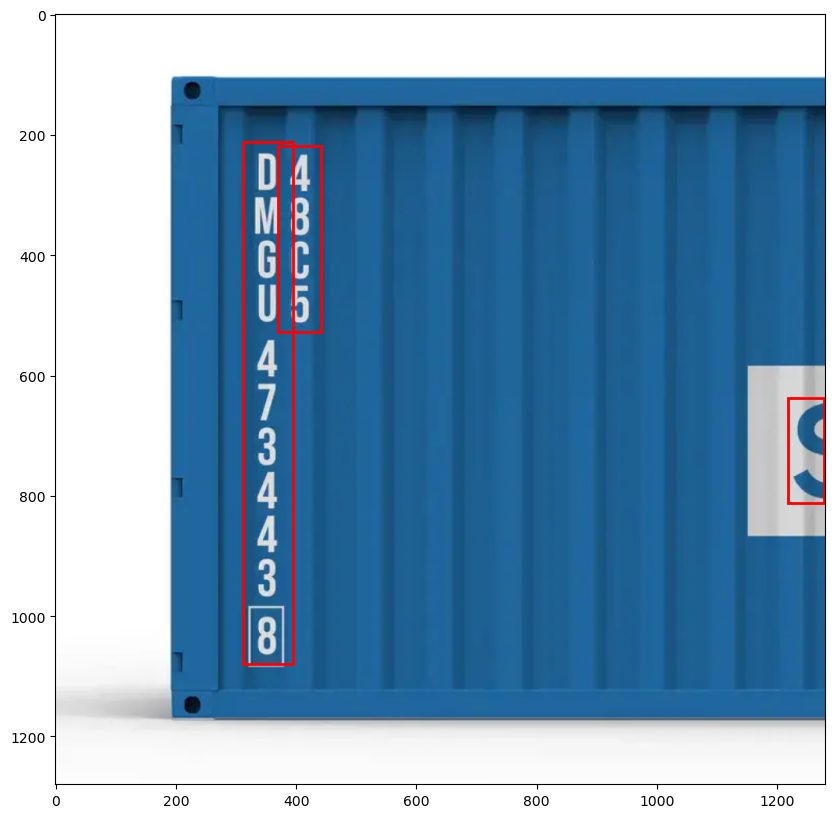

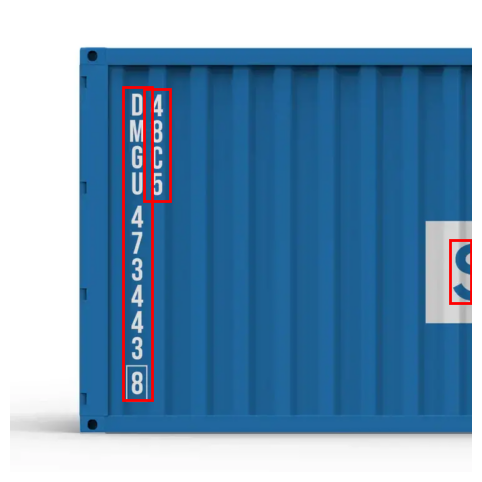

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.
[method.cpp:941] Output 1 is memory planned, or is a constant. Cannot override         the existing data pointer.


TEST


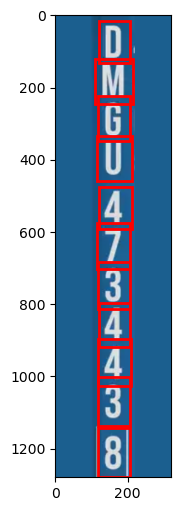

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.
[method.cpp:941] Output 1 is memory planned, or is a constant. Cannot override         the existing data pointer.


TEST


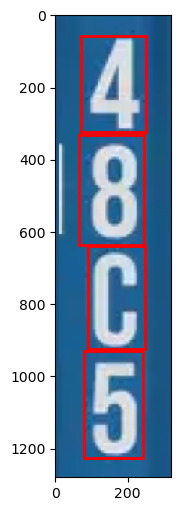

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.
[method.cpp:941] Output 1 is memory planned, or is a constant. Cannot override         the existing data pointer.


TEST


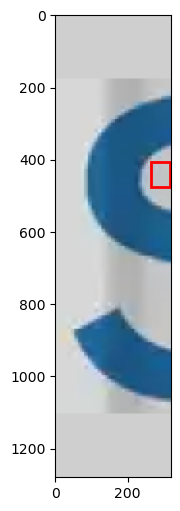

[program.cpp:134] InternalConsistency verification requested but not available
[program.cpp:134] InternalConsistency verification requested but not available


thresh type 0


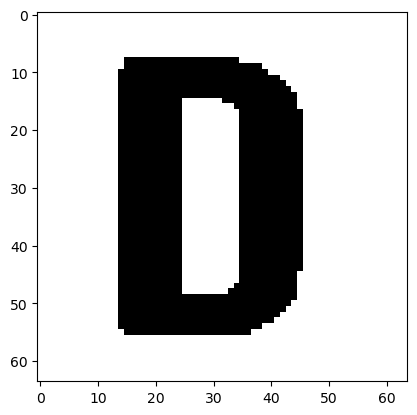

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
0 0.7072824380586304
thresh type 0


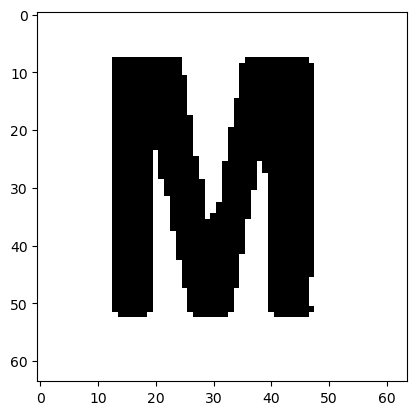

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
M 0.9975350806310104
thresh type 0


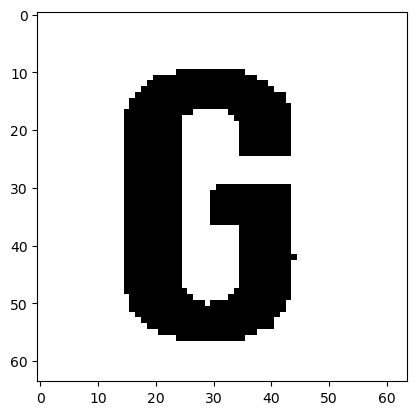

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
6 0.31782000875870153
thresh type 0


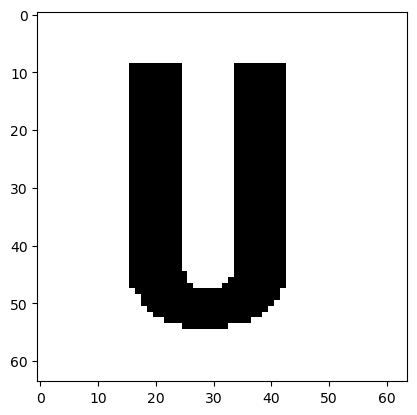

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
U 0.9911208244672167
thresh type 0


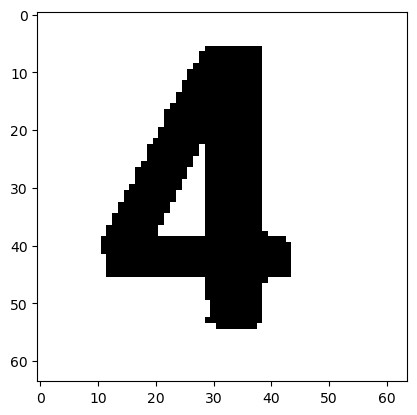

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
4 1.0
thresh type 0


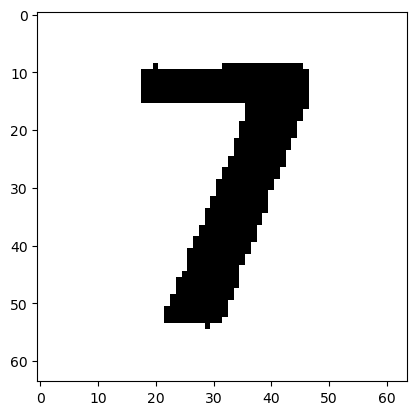

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
7 0.998579053562537
thresh type 0


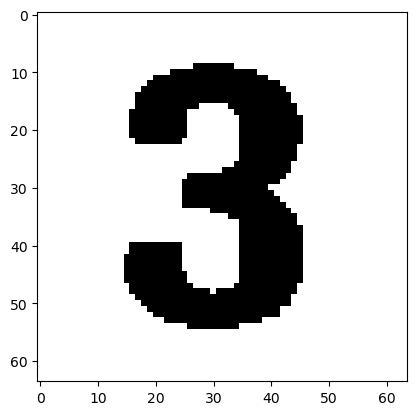

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
3 0.9999542241566814
thresh type 0


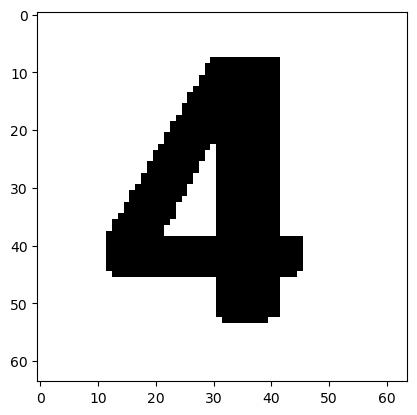

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
4 1.0
thresh type 0


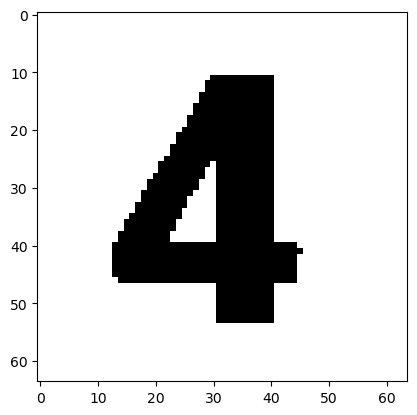

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
4 0.9999898847713415
thresh type 0


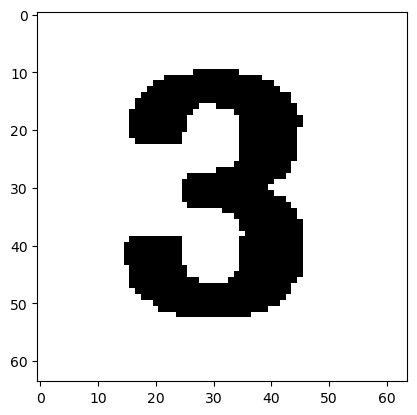

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
3 0.5388980334614669
thresh type 0


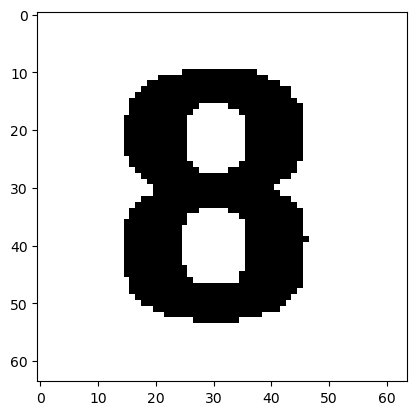

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
8 0.9999977350247811
thresh type 0


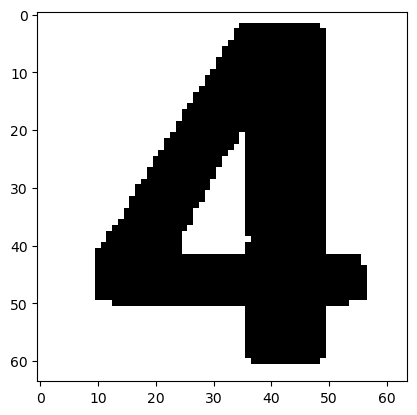

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
4 0.6024245041851635
thresh type 0


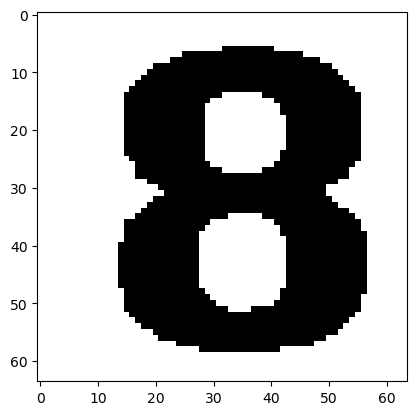

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
8 0.9776025786780368
thresh type 0


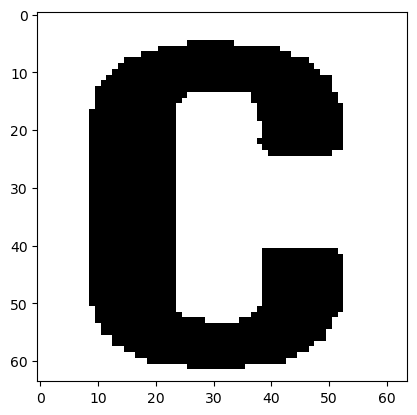

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
C 0.764423529164592
thresh type 0


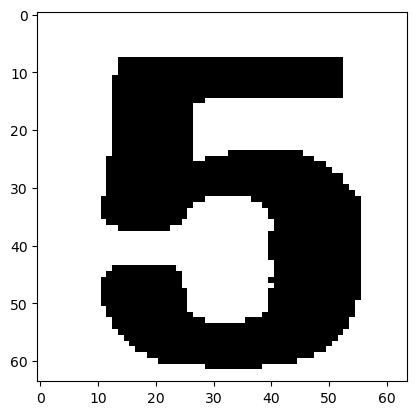

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
5 0.999917032055464
thresh type 1


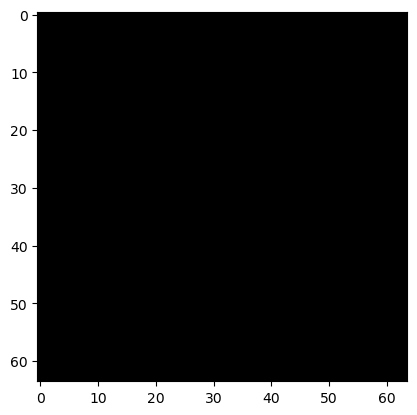

[method.cpp:941] Output 0 is memory planned, or is a constant. Cannot override         the existing data pointer.


torch.Size([1, 15, 97])
 0.0


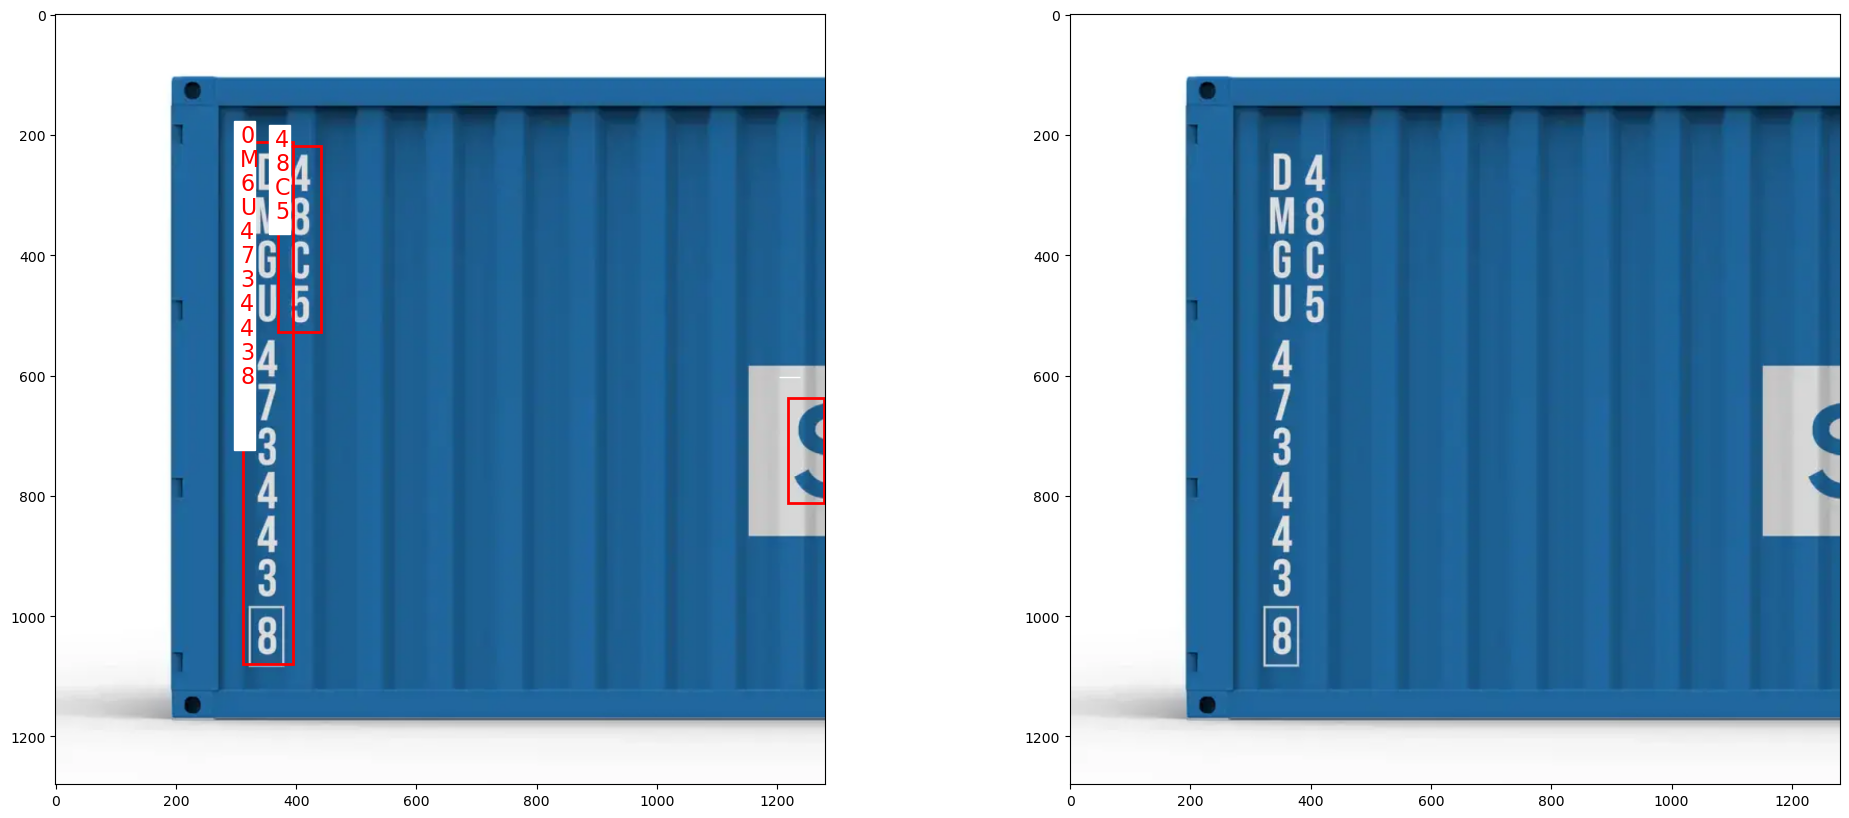

In [ ]:
IMAGE_SOURCE = "./cont_1.png"
INDEPENDENT_CHARACTERS = True

detector = Detector("./export/xnnpack_craft_1280.pte", "./export/xnnpack_craft_320.pte")

vertical_list = detector.run_detection(IMAGE_SOURCE)

recognizer = Recognizer(
    "./export/xnnpack_crnn_english_64.pte", "./export/xnnpack_crnn_english_512.pte"
)

result = recognizer.run_recognition(vertical_list)

img = cv2.imread(IMAGE_SOURCE, cv2.IMREAD_COLOR)
resized_img = OCRUtils.resize_with_padding(img, 1280, 1280)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(24, 10), dpi=100)
ax1.imshow(cv2.cvtColor(resized_img, cv2.COLOR_BGR2RGB))
for region in result:
    (p1, p2, p3, p4) = region["box"]
    rect = patches.Polygon((p1, p2, p3, p4), edgecolor="r", linewidth=2, fill=False)
    ax1.add_patch(rect)
    labels = [x[0] for x in region["characters"]]
    text = " ".join(labels)
    x, y = region["box"][0][0], region["box"][0][1]

    ax1.add_patch(
        patches.Rectangle(
            (x - 15, y - 35), 35, 26 * len(text), fill=True, color="white"
        )
    )
    for i, char in enumerate(text):
        ax1.text(x - 5, y + i * 20, char, fontsize=16, color="red")

ax2.imshow(cv2.cvtColor(resized_img, cv2.COLOR_BGR2RGB))

plt.show()

# final_text = [x[1] for x in result]

# final_text = ' '.join(final_text)

# print(final_text)